Наивный байесовский классификатор для фильтрации SMS-спама   
**Цель ноутбука** — реализация мультиномиальной и бернуллиевской моделей наивного Байеса, исследование влияния предобработки и сглаживания Лапласа на качество классификации.   
**Датасет:** [SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection) (UCI Machine Learning Repository) — 5 574 англоязычных SMS-сообщения, из них 747 спам (13,4%). Корпус собран из четырёх источников: 425 спам-сообщений с форума Grumbletext, 3 375 легитимных сообщений из NUS SMS Corpus (Сингапур), 450 легитимных сообщений из диссертации Caroline Tag и SMS Spam Corpus v.0.1 Big (1 002 ham + 322 spam).    
**Классы:** `ham` — легитимное сообщение, `spam` — нежелательное.   
**План работы:**
1) Загрузка и исследование данных.
2) Предобработка текстов.
3) Разделение на обучающую и тестовую выборки.
4) Мультиномиальная модель — обучение и оценка.
5) Модель Бернулли — обучение и оценка.
6) Сравнение моделей.
7) Подбор параметра сглаживания $\alpha$.
8) Анализ информативных признаков.
9) Пример классификации новых сообщений


**Примечание.** Для воспроизводимости достаточно библиотек `numpy`, `pandas`, `matplotlib`, `scikit-learn`. Стемминг и стоп-слова — из библиотеки `nltk`

In [1]:
# Регулярные выражения
import re

# Работа с zip-архивами
import zipfile

# Предобработка текста
import nltk

# Работа с табличными данными
import pandas as pd

# Для математических операций и визуального представления
import numpy as np
import matplotlib.pyplot as plt

# Векторизация текста (реализация Bag-of-Words)
from sklearn.feature_extraction.text import CountVectorizer

# Разделение выборки (train и test) и кросс-валидация
from sklearn.model_selection import train_test_split, cross_val_score

# Мультиномиальная модель и модель Бернулли
from sklearn.naive_bayes import MultinomialNB, BernoulliNB
from sklearn.pipeline import Pipeline

# Метрики
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                            f1_score, confusion_matrix, classification_report,
                            precision_recall_curve)

# Для воспроизводимости результата
RANDOM_STATE = 42

**Загрузка и исследование данных** 
Файл датасета — один текстовый файл `SMSSpamCollection`, где каждая строка имеет вид `метка<TAB>текст`.    
Загрузим скачанные данные из zip-архива.

In [2]:
# Открываем zip-архив
with zipfile.ZipFile("sms+spam+collection.zip") as zfile:

    # Заранее зная позицию файла, инициализируем ссылку на него
    sms_file = zfile.namelist()[0]

    # Октрываем файл и делаем из него pandas-таблицу
    with zfile.open(sms_file) as f:
        df = pd.read_csv(f, sep='\t', header=None, names=["Class", "Text"])
df

,Class,Text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [3]:
counts = df["Class"].value_counts()
counts

Class
ham     4825
spam     747
Name: count, dtype: int64


Датасет **несбалансирован**: спама в **6.46** меньше легитимных сообщений.   
Это ситуация часто встречается для задачи фильтрации спама.     
Посмотрим на распределение классов и длину сообщений


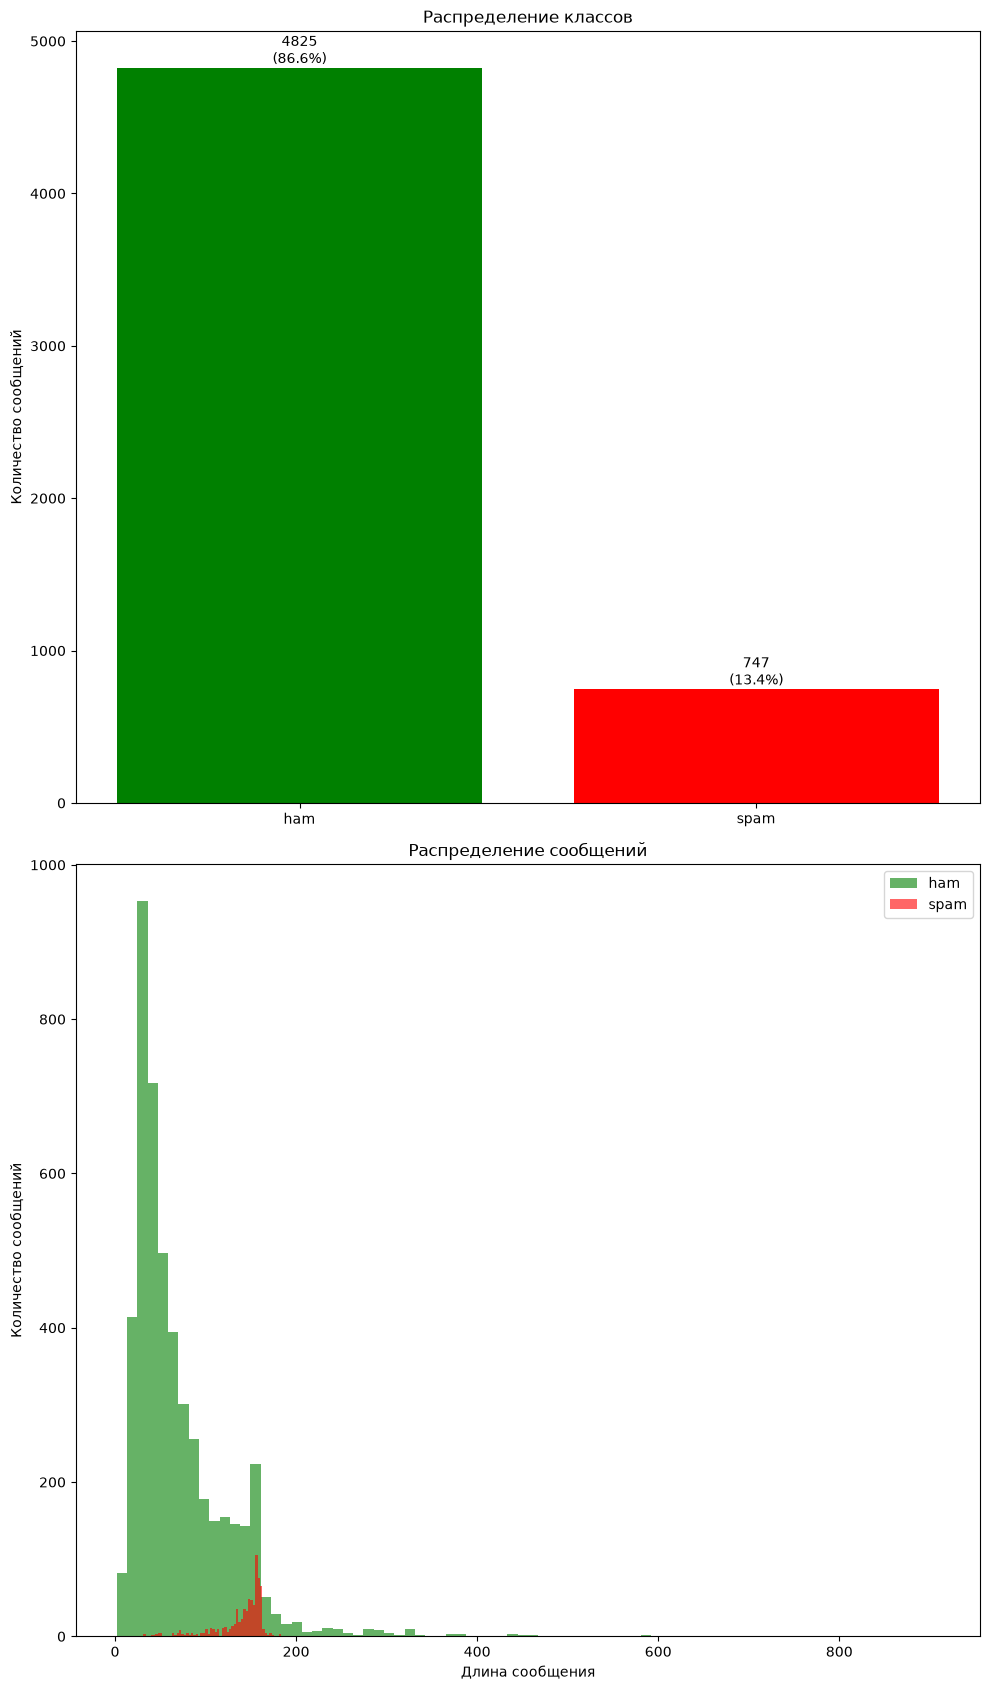

In [4]:
# Вывод графиков для первичного EDA

fig, axes = plt.subplots(2, 1, figsize=(10, 17))

# Столбчатая диаграмма
axes[0].bar(counts.index, counts.values, color=["g", "r"])

for ind, val in enumerate(counts.values):
    # 1: (0, 4825)
    # 2: (1, 747)
    
    # Подписи над столбцами
    axes[0].text(ind, val, f"{val}\n({val / len(df):.1%})", ha="center", va="bottom")

# Подписи первого графика
axes[0].set_title("Распределение классов")
axes[0].set_ylabel("Количество сообщений")

# Добавление дополнительного столбца в таблицу: длина сообщения
df["length"] = df["Text"].str.len()


for label, color in [("ham", "g"), ("spam", "r")]:

    # Гистрограмма для каждого из классов
    axes[1].hist(df.loc[df["Class"] == label, "length"], bins=80,
                 alpha=0.6, label=label, color=color)

# Подписи и легенда для второго графика    
axes[1].set_title("Распределение сообщений")
axes[1].set_ylabel("Количество сообщений")
axes[1].set_xlabel("Длина сообщения")
axes[1].legend()

# Автоматичекая подгонка отступов, чтобы подписи не наезжали
plt.tight_layout()   
plt.show()

**Вывод по EDA:**    
Спам-сообщения в среднем длиннее легитимных в 1.9 раз(видно по гистограмме и нижеприведённому коду) — длина сама по себе является информативным признаком, хотя в рамках наивного Байеса здесь используются только словесные признаки.

In [5]:
ham = df[df["Class"] == "ham"]["length"]
print(f"Средняя длина сообщений для класса \"ham\": {ham.mean()}")

Средняя длина сообщений для класса "ham": 71.48248704663213


In [6]:
spam = df[df["Class"] == "spam"]["length"]
print(f"Средняя длина сообщений для класса \"spam\": {spam.mean()}")

Средняя длина сообщений для класса "spam": 138.6706827309237


**Предварительная обработка текстов**  
Реализуем пайплайн предобработки:
1) Приведение к нижнему регистру,
2) Замена спам-характерных элементов (URL, номера телефонов, денежные суммы) на маркеры `<url>`, `<phone>`, `<money>`,
3) Токенизация
4) Удаление стоп-слов,
5) Стемминг

In [7]:
# Функция preprocess будет использоваться в качестве analyzer в векторизаторе CountVectorizer

# Скачивание около 200 английских стоп-слов
nltk.download("stopwords", quiet=True)
STOP_WORDS = set(nltk.corpus.stopwords.words("english"))

# Стемминг
stemming = nltk.stem.PorterStemmer().stem

def preprocess(text: str) -> list:
    
    text = text.lower()

    # Замена спам-сигналов на маркеры с помощью регулярных выражений
    text = re.sub(r"https?://\S+|www\.\S+", " <url> ", text) # Замена ссылки
    text = re.sub(r"(?<!\w)(?:\+?\d[\d\s().-]{6,}\d)(?!\w)", " <phone> ", text) # Замена номера телефона
    text = re.sub(r"(?:[$£€]\s?\d+(?:[.,]\d+)?|\d+(?:[.,]\d+)?\s?[$£€])", " <money> ", text) # Замена денежной суммы

    # Очистка лишних символов
    text = re.sub(r"[^a-z<>\d]+", " ", text)

    tokens = []
    for token in text.split():

        # Стоп слова пропускаются
        if token in STOP_WORDS:
            continue
        
        # Маркеры не стеммируются
        if token.startswith("<") and token.endswith(">"):
            tokens.append(token)    

        # Любое другие элементы стеммируются
        elif re.search(r"[a-z]", token) or token.isdigit():
            tokens.append(stemming(token))
        
    return tokens

**Разделение на обучающую и тестовую выборки**  
Стратифицированное разделение 80/20 с фиксированным `random_state` для воспроизводимости: состав тестовой выборки по классам пропорционален исходному.

In [8]:
# 1 = spam, 0 = ham
y = (df["Class"] == "spam").astype(int)   

# Разбиение с сохранением пропорции целевого класса (stratify)
X_train, X_test, y_train, y_test = train_test_split(
    df["Text"], y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

# Проверка на корректность разбиения
print(f"Обучающая выборка: {len(X_train)} сообщений "
      f"([{int(y_train.sum())} spam, {round(y_train.sum() / len(X_train) * 100,1)}%]", 
      f"[{len(y_train) - int(y_train.sum())} ham, " 
      f"{round((len(y_train) - int(y_train.sum())) / len(X_train) * 100,1)}%])")

print(f"Тестовая выборка: {len(X_test)} сообщений "
      f"([{int(y_test.sum())} spam, {round(y_test.sum() / len(X_test) * 100,1)}%]", 
      f"[{len(y_test) - int(y_test.sum())} ham, " 
      f"{round((len(y_test) - int(y_test.sum())) / len(X_test) * 100,1)}%])")

Обучающая выборка: 4457 сообщений ([598 spam, 13.4%] [3859 ham, 86.6%])
Тестовая выборка: 1115 сообщений ([149 spam, 13.4%] [966 ham, 86.6%])


**Мультиномиальная модель (Multinomial Naive Bayes)**   
Документ — вектор частот слов, правдоподобие — мультиномиальное распределение, решение — правило MAP, сглаживание Лапласа α = 1.    
Класс `MultinomialNB` sklearn обучается именно на частотах (`CountVectorizer` по умолчанию), все вычисления ведутся в логарифмической форме.

In [9]:
#Обучение мультиномиального классификатора и его оценка

pipe_multi = Pipeline([
    ("vectorizer", CountVectorizer(analyzer=preprocess)), # Bag-of-Words
    ("classifier", MultinomialNB(alpha=1.0)),
])

# Обучение модели
pipe_multi.fit(X_train, y_train)

# Предсказания модели на тестовой выборке
proba_multi = pipe_multi.predict_proba(X_test)[:, 1]
pred_multi = (proba_multi >= 0.5).astype(int) # Если больше 50%, значит это ответ


**Модель Бернулли (Bernoulli Naive Bayes)**   
Документ — бинарный вектор признаков «слово есть / слова нет».    
В sklearn это `BernoulliNB` вместе с `CountVectorizer(binary=True)`: многократные повторения слова игнорируются.

In [10]:
#Обучение классификатора Бернулли и его оценка

pipe_bern = Pipeline([
    ("vectorizer", CountVectorizer(analyzer=preprocess, binary=True)),
    ("classifier", BernoulliNB(alpha=1.0)),
])

# Обучение модели
pipe_bern.fit(X_train, y_train)

# Предсказания модели на тестовой выборке
proba_bern = pipe_bern.predict_proba(X_test)[:, 1]
pred_bern = (proba_bern >= 0.5).astype(int) # Если больше 50%, значит это ответ

**Сравнение моделей и матрицы ошибок**   
Сводная таблица метрик (поизитивный класс - spam) и матрицы ошибок. Для задачи спам-фильтрации наиболее критичен **пропуск spam** (FN: спам попал во входящие), поэтому в первую очередь смотрим на `recall` по классу spam.   
Также серьёзной ошибкой является **ложная блокировка ham** (FP), поэтому стоит уделить внимание и `precision`.

In [11]:
# Результирующая таблица оценок моделей
results = pd.DataFrame([
    {"Модель": "Мультиномиальная (alpha=1)",
     "Accuracy": accuracy_score(y_test, pred_multi),
     "Precision": precision_score(y_test, pred_multi, zero_division=0),
     "Recall": recall_score(y_test, pred_multi),
     "F1": f1_score(y_test, pred_multi)},
    {"Модель": "Бернулли (alpha=1)",
     "Accuracy": accuracy_score(y_test, pred_bern),
     "Precision": precision_score(y_test, pred_bern, zero_division=0),
     "Recall": recall_score(y_test, pred_bern),
     "F1": f1_score(y_test, pred_bern)},
]).set_index("Модель").round(4)

results

,Accuracy,Precision,Recall,F1
Модель,,,,
Мультиномиальная (alpha=1),0.9857,0.9586,0.9329,0.9456
Бернулли (alpha=1),0.9821,0.9850,0.8792,0.9291


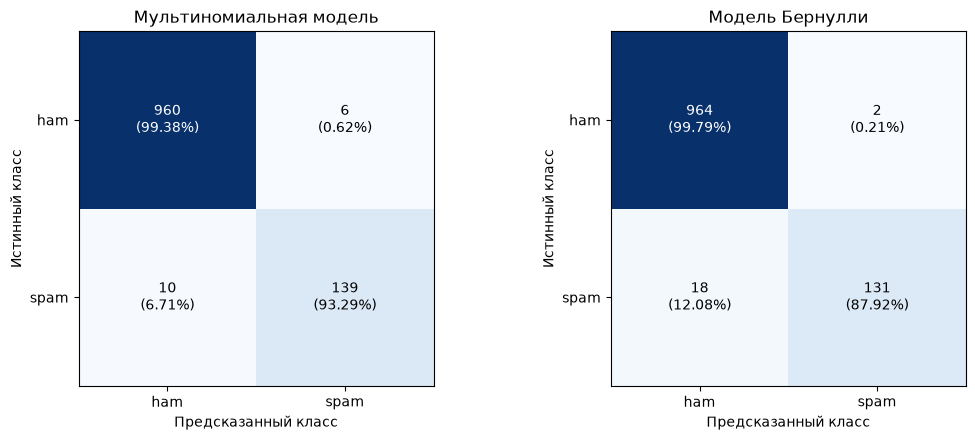

In [12]:
# Вывод матрицы ошибок для каждой из моделей


def plot_confusion(cm: np.ndarray, ax: plt.Axes, title: str) -> None:
    """
    Рисует матрицу ошибок 2×2 на заданной оси.

    Параметры:
    * cm : np.ndarray, shape (2, 2)
        Матрица ошибок: cm[i, j] — сколько примеров истинного класса i
        предсказано как класс j. Порядок классов — [ham, spam].
    * ax : plt.Axes
        Ось matplotlib, на которой рисовать.
    * title : str
        Заголовок панели.
    """

    # Построение матрицы
    ax.imshow(cm, cmap="Blues")

    # Заполнение ячеек
    for (i, j), val in np.ndenumerate(cm):
        ax.text(j, i, f"{val}\n({val / cm[i].sum():.2%})", ha="center", va="center",
                color="white" if val > cm.max() * 0.6 else "black")

    # Редактирование подписей
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["ham", "spam"]); ax.set_yticklabels(["ham", "spam"])
    ax.set_xlabel("Предсказанный класс"); ax.set_ylabel("Истинный класс")
    ax.set_title(title)


# Отрисовка матриц
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_confusion(confusion_matrix(y_test, pred_multi), axes[0], "Мультиномиальная модель")
plot_confusion(confusion_matrix(y_test, pred_bern), axes[1], "Модель Бернулли")
plt.tight_layout()
plt.show()

**Вывод по сравнению моделей**   
Мультиномиальная и Бернуллевская модель имеют высокие показатели точности, однако F-1 мера у первой модели на 0.0165 выше, чем у модели Бернулли. Эти данные согласуются с [классической работой McCallum & Nigam](http://www.cs.cmu.edu/~dgovinda/pdf/multinomial-aaaiws98.pdf): для классификации текстов мультиномиальная модель, использующая частоты, обычно превосходит модель Бернулли, теряющую информацию о повторяемости слов.

Попытаемся увеличить точность модели скорректировав параметр $\alpha$

In [13]:
# Подбор гиперпараметра alpha с помощью cross-validation для мультиномиальной модели

# alpha выбирается в диапозоне от 0.0001 до 10
alphas = np.logspace(-4, 1, 27)

# F-1 метрика модели при разных альфа
cv_scores_multi = []
cv_scores_bern = []


for alpha in alphas:
    # Обучение Мультиномиальной модели при разных alpha
    pipe_multi = Pipeline([
        ("vectorizer", CountVectorizer(analyzer=preprocess)),
        ("classifier", MultinomialNB(alpha=alpha)),
    ])
    cv_scores_multi.append(cross_val_score(pipe_multi, X_train, y_train,
                                     cv=5, scoring="f1").mean())

    # Обучение модели Бернулли при разных alpha
    pipe_bern = Pipeline([
        ("vectorizer", CountVectorizer(analyzer=preprocess)),
        ("classifier", BernoulliNB(alpha=alpha)),
    ])
    cv_scores_bern.append(cross_val_score(pipe_bern, X_train, y_train,
                                     cv=5, scoring="f1").mean())

best_alpha_multi = alphas[int(np.argmax(cv_scores_multi))]
print(f"Оптимальное alpha для мультиномиальной модели = {best_alpha_multi:.4f}, CV F1 = {max(cv_scores_multi):.4f}")

best_alpha_bern = alphas[int(np.argmax(cv_scores_bern))]
print(f"Оптимальное alpha для модели Бернулли = {best_alpha_bern:.4f}, CV F1 = {max(cv_scores_bern):.4f}")

Оптимальное alpha для мультиномиальной модели = 0.7017, CV F1 = 0.9572
Оптимальное alpha для модели Бернулли = 0.0492, CV F1 = 0.9637


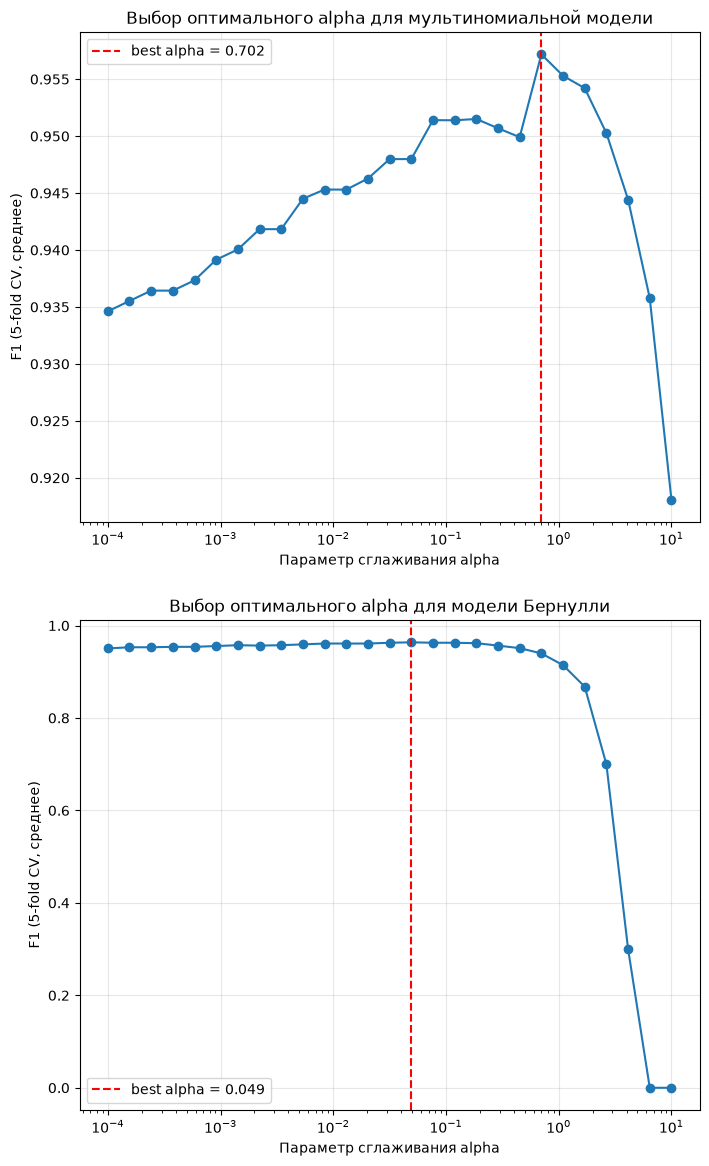

In [14]:
# График обоснования выбора конкретных альфа для моделей

fig, axes = plt.subplots(2, 1, figsize=(8, 14))

# График для мультиномиальной модели
axes[0].semilogx(alphas, cv_scores_multi, marker="o")
axes[0].axvline(best_alpha_multi, color="r", linestyle="--",
            label=f"best alpha = {best_alpha_multi:.3f}")
axes[0].set_xlabel("Параметр сглаживания alpha")
axes[0].set_ylabel("F1 (5-fold CV, среднее)")
axes[0].set_title("Выбор оптимального alpha для мультиномиальной модели")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# График для модели Бернулли
axes[1].semilogx(alphas, cv_scores_bern, marker="o")
axes[1].axvline(best_alpha_bern, color="r", linestyle="--",
            label=f"best alpha = {best_alpha_bern:.3f}")
axes[1].set_xlabel("Параметр сглаживания alpha")
axes[1].set_ylabel("F1 (5-fold CV, среднее)")
axes[1].set_title("Выбор оптимального alpha для модели Бернулли")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.show()

In [15]:
# Обучение при оптимальных alpha
pipe_multi_best = Pipeline([
    ("vectorizer", CountVectorizer(analyzer=preprocess)),
    ("classifier", MultinomialNB(alpha=best_alpha_multi)),
])
pipe_bern_best = Pipeline([
    ("vectorizer", CountVectorizer(analyzer=preprocess)),
    ("classifier", BernoulliNB(alpha=best_alpha_bern)),
])

pipe_multi_best.fit(X_train, y_train)
pipe_bern_best.fit(X_train, y_train)

# Предсказания на тестовой выборке
proba_multi_best = pipe_multi_best.predict_proba(X_test)[:, 1]
pred_multi_best  = (proba_multi_best >= 0.5).astype(int)

proba_bern_best = pipe_bern_best.predict_proba(X_test)[:, 1]
pred_bern_best  = (proba_bern_best >= 0.5).astype(int)


# Результирующая таблица оценок моделей
new_results = pd.DataFrame([
    {"Модель": f"Мультиномиальная (alpha={best_alpha_multi:.3f})",
     "Accuracy": accuracy_score(y_test, pred_multi_best),
     "Precision": precision_score(y_test, pred_multi_best, zero_division=0),
     "Recall": recall_score(y_test, pred_multi_best),
     "F1": f1_score(y_test, pred_multi_best)},
    {"Модель": f"Бернулли (alpha={best_alpha_bern:.3f})",
     "Accuracy": accuracy_score(y_test, pred_bern_best),
     "Precision": precision_score(y_test, pred_bern_best, zero_division=0),
     "Recall": recall_score(y_test, pred_bern_best),
     "F1": f1_score(y_test, pred_bern_best)},
]).set_index("Модель").round(4)

new_results

,Accuracy,Precision,Recall,F1
Модель,,,,
Мультиномиальная (alpha=0.702),0.9857,0.9586,0.9329,0.9456
Бернулли (alpha=0.049),0.9892,0.9928,0.9262,0.9583


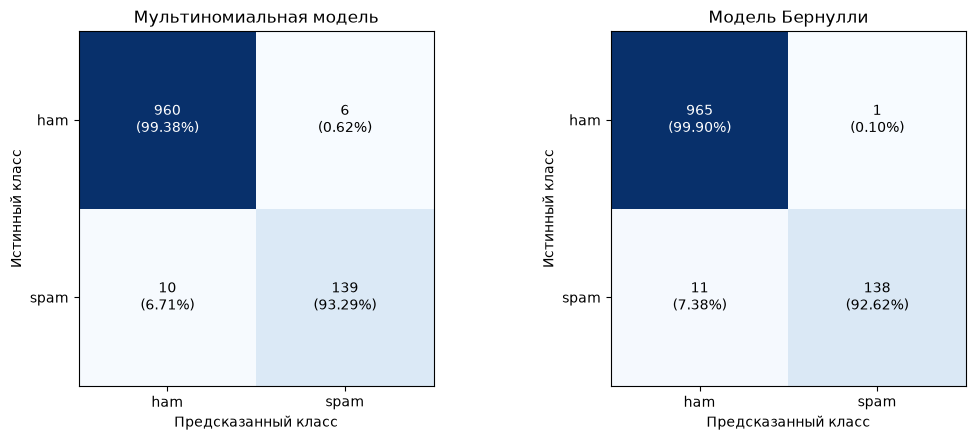

In [16]:
# Отрисовка матриц c оптимальными альфа
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_confusion(confusion_matrix(y_test, pred_multi_best), axes[0], "Мультиномиальная модель")
plot_confusion(confusion_matrix(y_test, pred_bern_best), axes[1], "Модель Бернулли")
plt.tight_layout()
plt.show()

**Вывод по сравнению моделей после подбора оптимального $\alpha$**      
Подбор гиперпараметра $\alpha$ для BernoulliNB позволил снизить количество ложноположительных срабатываний (False Positives) с 18 до 11, тем самым повысив Precision до 99.28%. Хотя полнота (Recall) незначительно снизилась (с 93.29% до 92.62%), итоговая F1-мера выросла. Это объясняется тем, что BernoulliNB чувствительна к сглаживанию и явно моделирует отсутствие бинарных признаков (маркеров `<url>`, `<phone>`), что критически важно для коротких SMS. Для MultinomialNB подбор $\alpha$ не дал изменений, так как дефолтное значение 1.0 уже находится в оптимальной зоне.

**Пример работы классификатора**   
Применим итоговую модель к нескольким/ новым сообщениям (в том числе к «хитрым»: спам без явных спам-слов и легитимному сообщению со словом free).

In [17]:
examples = [
    "Congratulations! You won a FREE prize. Call now to claim £1000!",
    "Hey, are we still meeting tomorrow to discuss the project?",
    "URGENT! Your account has been blocked. Verify now at http://secure-bank-login.com",
    "Can you pick up some bread on your way home? It's free parking after 6pm.",
]

proba = pipe_bern_best.predict_proba(examples)[:, 1]
out = pd.DataFrame({"Сообщение": examples,
                    "P(spam | X)": np.round(proba, 4),
                    "Решение": np.where(proba >= 0.5, "SPAM", "HAM")})
out

,Сообщение,P(spam | X),Решение
0,Congratulations! You won a FREE prize. Call no...,1.0000,SPAM
1,"Hey, are we still meeting tomorrow to discuss ...",0.0000,HAM
2,URGENT! Your account has been blocked. Verify ...,0.9988,SPAM
3,Can you pick up some bread on your way home? I...,0.0000,HAM
